DATASET OVERVIEW
   StudentID  Gender       City CollegeTier Stream Specialisation Hostel  \
0          1    Male  Ahmedabad       Tier2    ECE     Networking     No   
1          2  Female     Mumbai       Tier2    ECE    DataScience    Yes   
2          3    Male    Kolkata       Tier2     IT    DataScience    Yes   
3          4    Male     Jaipur       Tier1     CS             AI     No   
4          5    Male       Pune       Tier2     IT    DataScience    Yes   

  HistoryOfBacklogs  SGPA_Sem1  SGPA_Sem2  ...  Publications  \
0                No       6.02       6.54  ...             0   
1               Yes       5.84       5.12  ...             0   
2                No       4.91       5.29  ...             0   
3                No       7.67       8.03  ...             0   
4                No       8.14       8.97  ...             1   

   AptitudeTestScore  SoftSkillsRating  CodingTestScore  MockInterviewScore  \
0               66.7               2.2             49.4       

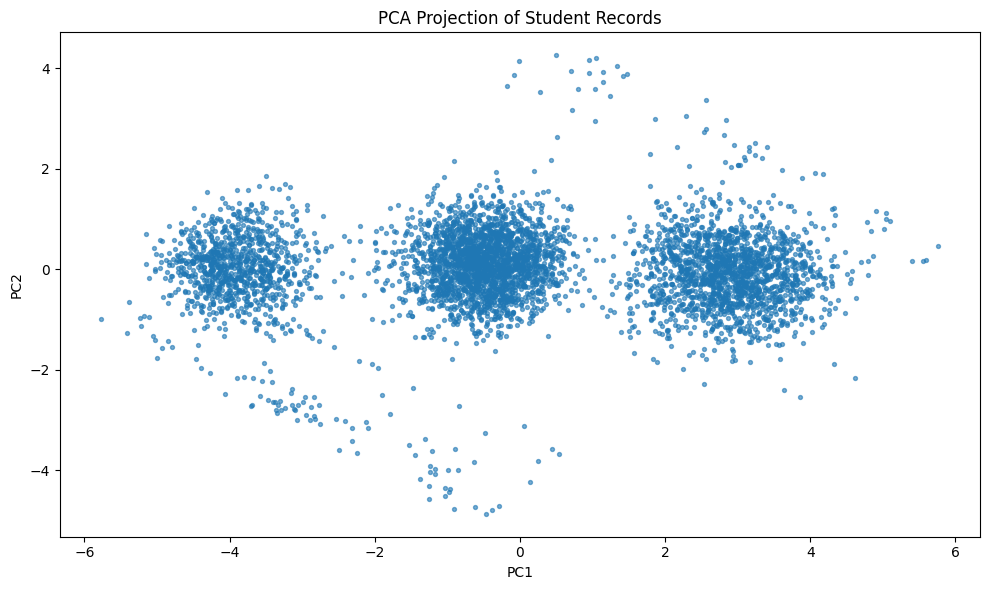

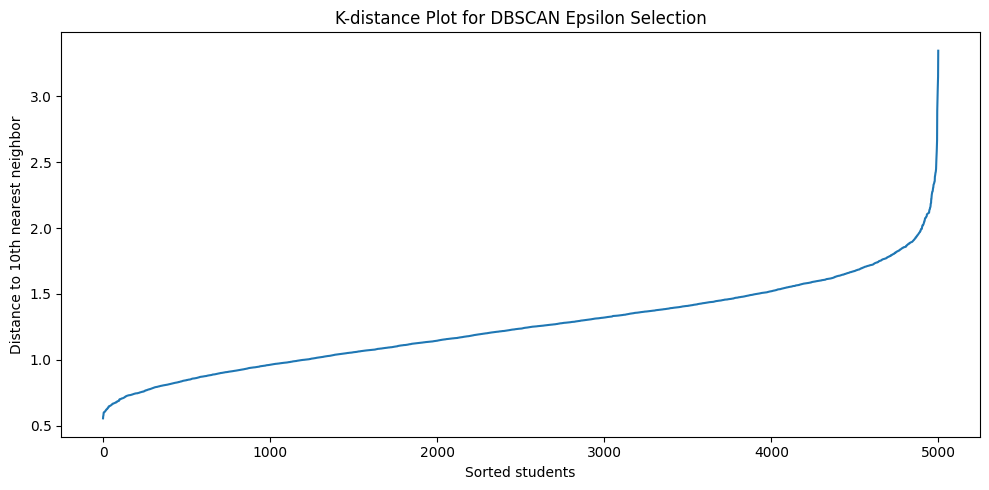


DBSCAN RESULTS
Epsilon: 2.2 minPts: 10
Clusters: 1
Outliers: 8
Cluster counts:
 DBSCAN_Cluster
-1       8
 0    4992
Name: count, dtype: int64


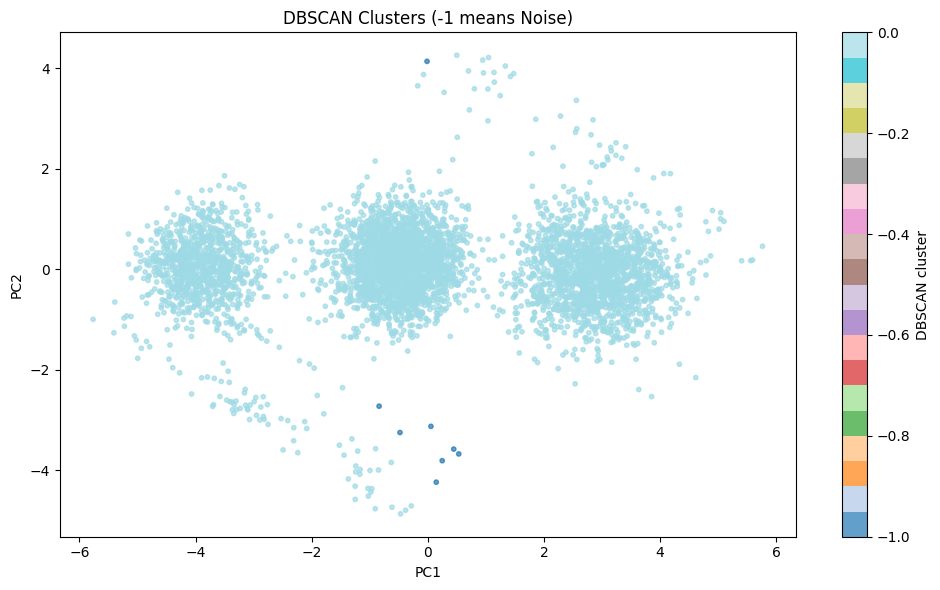


ISOLATION FOREST RESULTS
Detected outliers: 250
Outlier overlap with DBSCAN: 8


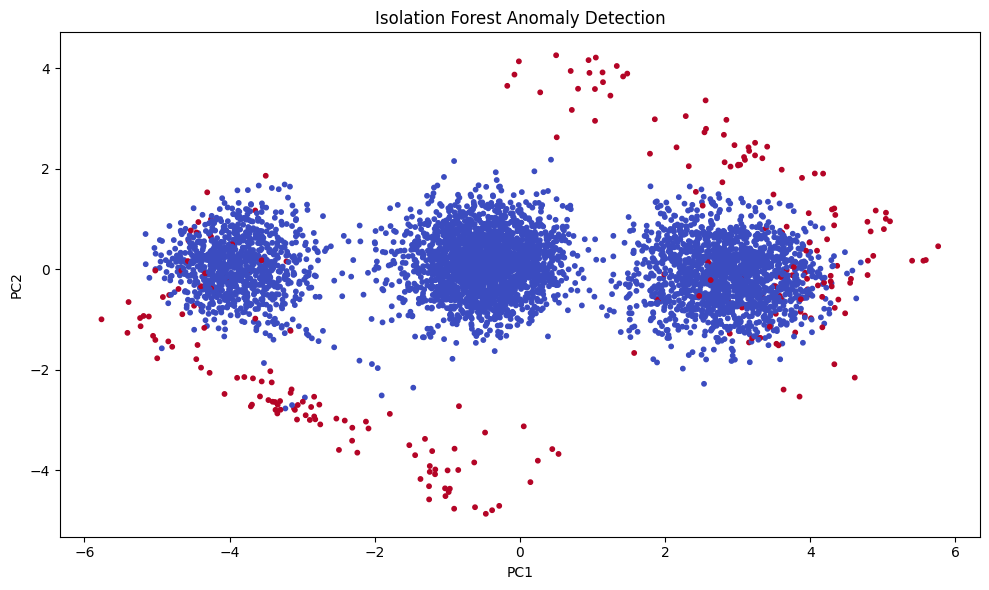


Average features by DBSCAN cluster:
                CGPA  AttendancePercent  Internships  Projects  Workshops  \
DBSCAN_Cluster                                                              
-1              4.87              55.32         1.75      3.75       2.62   
 0              7.23              76.52         1.12      2.08       1.79   

                Certifications  AptitudeTestScore  SoftSkillsRating  \
DBSCAN_Cluster                                                        
-1                        3.00              47.64              3.65   
 0                        1.94              68.62              3.14   

                CodingTestScore  MockInterviewScore  
DBSCAN_Cluster                                       
-1                         7.23               66.00  
 0                        57.18               55.44  

Sample unusual records:
       StudentID  CGPA  AttendancePercent  Internships  Projects  Workshops  \
8877        8878  4.15          52.152796        

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

FILE = 'placement_predict_50k Dataset.csv'
df = pd.read_csv(FILE)
print('DATASET OVERVIEW')
print(df.head())
print('Shape:', df.shape)
print('Missing values:\n', df.isna().sum())
features = ['CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops',
            'Certifications', 'AptitudeTestScore', 'SoftSkillsRating',
            'CodingTestScore', 'MockInterviewScore']
X = df[features].copy()
X = SimpleImputer(strategy='median').fit_transform(X)
X = StandardScaler().fit_transform(X)

# DBSCAN can be expensive on 50,000 rows; sample reproducibly.
SAMPLE_SIZE = min(5000, len(df))
rng = np.random.default_rng(42)
indices = np.sort(rng.choice(len(df), size=SAMPLE_SIZE, replace=False))
X_sample = X[indices]
result = df.iloc[indices].copy()

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_sample)
print('\nPCA explained variance:', pca.explained_variance_ratio_)
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=8, alpha=0.6)
plt.title('PCA Projection of Student Records')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('exp9_pca.png', dpi=150)
plt.show()

min_pts = 10
neighbors = NearestNeighbors(n_neighbors=min_pts)
neighbors.fit(X_sample)
distances, _ = neighbors.kneighbors(X_sample)
k_distances = np.sort(distances[:, -1])
plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title('K-distance Plot for DBSCAN Epsilon Selection')
plt.xlabel('Sorted students')
plt.ylabel('Distance to 10th nearest neighbor')
plt.tight_layout()
plt.savefig('exp9_k_distance.png', dpi=150)
plt.show()

# Tune epsilon based on the elbow in the k-distance graph.
epsilon = 2.2
model = DBSCAN(eps=epsilon, min_samples=min_pts)
labels = model.fit_predict(X_sample)
result['DBSCAN_Cluster'] = labels
n_clusters = len(set(labels) - {-1})
n_noise = int((labels == -1).sum())
print('\nDBSCAN RESULTS')
print('Epsilon:', epsilon, 'minPts:', min_pts)
print('Clusters:', n_clusters)
print('Outliers:', n_noise)
print('Cluster counts:\n', result['DBSCAN_Cluster'].value_counts().sort_index())
if n_clusters >= 2 and n_noise < len(labels):
    mask = labels != -1
    if len(set(labels[mask])) >= 2:
        print('Silhouette score:', silhouette_score(X_sample[mask], labels[mask], sample_size=min(2000, mask.sum()), random_state=42))
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab20', s=10, alpha=0.7)
plt.title('DBSCAN Clusters (-1 means Noise)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='DBSCAN cluster')
plt.tight_layout()
plt.savefig('exp9_dbscan.png', dpi=150)
plt.show()

iso = IsolationForest(n_estimators=150, contamination=0.05, random_state=42)
iso_labels = iso.fit_predict(X_sample)
result['IsolationForest_Outlier'] = (iso_labels == -1).astype(int)
result['IsolationForest_Score'] = iso.decision_function(X_sample)
print('\nISOLATION FOREST RESULTS')
print('Detected outliers:', result['IsolationForest_Outlier'].sum())
print('Outlier overlap with DBSCAN:', ((labels == -1) & (iso_labels == -1)).sum())
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=result['IsolationForest_Outlier'], cmap='coolwarm', s=10)
plt.title('Isolation Forest Anomaly Detection')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('exp9_isolation_forest.png', dpi=150)
plt.show()

print('\nAverage features by DBSCAN cluster:')
print(result.groupby('DBSCAN_Cluster')[features].mean().round(2))
print('\nSample unusual records:')
print(result.loc[result['DBSCAN_Cluster'] == -1, ['StudentID'] + features].head(10))
result.to_csv('experiment9_cluster_results.csv', index=False)
print('\nSaved results to experiment9_cluster_results.csv')